# Clustering Track

## 1. Setup

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="colorblind")
PALETTE = "tab10"
os.makedirs("../figures", exist_ok=True)
os.makedirs("../models", exist_ok=True)

DATA_PATH = "../data/clustering.csv"
K_RANGE = range(2, 11)

## 2. Data loading and audit

In [ ]:
df = pd.read_csv(DATA_PATH)
bool_cols = df.select_dtypes(bool).columns
df[bool_cols] = df[bool_cols].astype(int)      # True/False -> 1/0
print("Shape:", df.shape)
df.head()

Shape: (1243, 42)


,inches,ram,weight,is_ips,is_touchscreen,res_width,res_height,storage_gb,has_ssd,has_hdd,...,typename_Ultrabook,typename_Workstation,opsys_Chrome Os,opsys_Linux,opsys_Mac Os X,opsys_Macos,opsys_No Os,opsys_Windows 10,opsys_Windows 10 S,opsys_Windows 7
0,13.3,8.0,1.37,1,0,2560,1600,128.0,1,0,...,1,0,0,0,0,1,0,0,0,0
1,13.3,8.0,1.34,0,0,1440,900,128.0,0,0,...,1,0,0,0,0,1,0,0,0,0
2,15.6,8.0,1.86,0,0,1920,1080,256.0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,15.4,16.0,1.83,1,0,2880,1800,512.0,1,0,...,1,0,0,0,0,1,0,0,0,0
4,13.3,8.0,1.37,1,0,2560,1600,256.0,1,0,...,1,0,0,0,0,1,0,0,0,0


In [ ]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "n_unique": df.nunique(),
    "min": df.min(), "max": df.max(),
})
print("Total missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", df.duplicated().sum())
audit

Total missing values: 0
Duplicate rows: 248


,dtype,missing,n_unique,min,max
inches,float64,0,24,10.100000,35.600000
ram,float64,0,10,1.000000,64.000000
weight,float64,0,157,0.255000,3.575000
is_ips,int64,0,2,0.000000,1.000000
is_touchscreen,int64,0,2,0.000000,1.000000
res_width,int64,0,13,1366.000000,3840.000000
res_height,int64,0,10,768.000000,2160.000000
storage_gb,float64,0,22,8.000000,2560.000000
has_ssd,int64,0,2,0.000000,1.000000
has_hdd,int64,0,2,0.000000,1.000000


### Feature groups
The 42 columns fall into four groups:
- **Continuous specs:** `inches, ram, weight, res_width, res_height, storage_gb, ppi`
- **Binary hardware flags:** `is_ips, is_touchscreen, has_ssd, has_hdd`
- **One-hot brand / OS:** `company_*`, `opsys_*` — kept for describing clusters afterwards
- **One-hot laptop type:** `typename_*` — reference labels, held out of fitting

In [ ]:
CONT_COLS  = ["inches", "ram", "weight", "res_width", "res_height", "storage_gb", "ppi"]
FLAG_COLS  = ["is_ips", "is_touchscreen", "has_ssd", "has_hdd"]
BRAND_COLS = [c for c in df.columns if c.startswith("company_")]
OS_COLS    = [c for c in df.columns if c.startswith("opsys_")]
TYPE_COLS  = [c for c in df.columns if c.startswith("typename_")]
assert len(CONT_COLS + FLAG_COLS + BRAND_COLS + OS_COLS + TYPE_COLS) == df.shape[1]

def collapse(frame, cols, prefix):
    """Turn a one-hot block back into a single categorical column (for EDA and profiling)."""
    return frame[cols].idxmax(axis=1).str.replace(prefix, "", regex=False)

df["brand"] = collapse(df, BRAND_COLS, "company_")
df["os"]    = collapse(df, OS_COLS, "opsys_")
df["type"]  = collapse(df, TYPE_COLS, "typename_")
df[CONT_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
inches,1243.0,15.14,1.97,10.10,14.00,15.60,15.60,35.60
ram,1243.0,8.53,5.59,1.00,4.00,8.00,8.00,64.00
weight,1243.0,2.03,0.62,0.25,1.50,2.04,2.33,3.58
res_width,1243.0,1900.01,493.03,1366.00,1920.00,1920.00,1920.00,3840.00
res_height,1243.0,1073.92,283.85,768.00,1080.00,1080.00,1080.00,2160.00
storage_gb,1243.0,622.36,483.63,8.00,256.00,500.00,1024.00,2560.00
ppi,1243.0,146.39,43.32,44.02,127.34,141.21,157.35,352.47


## 3. Exploratory data analysis

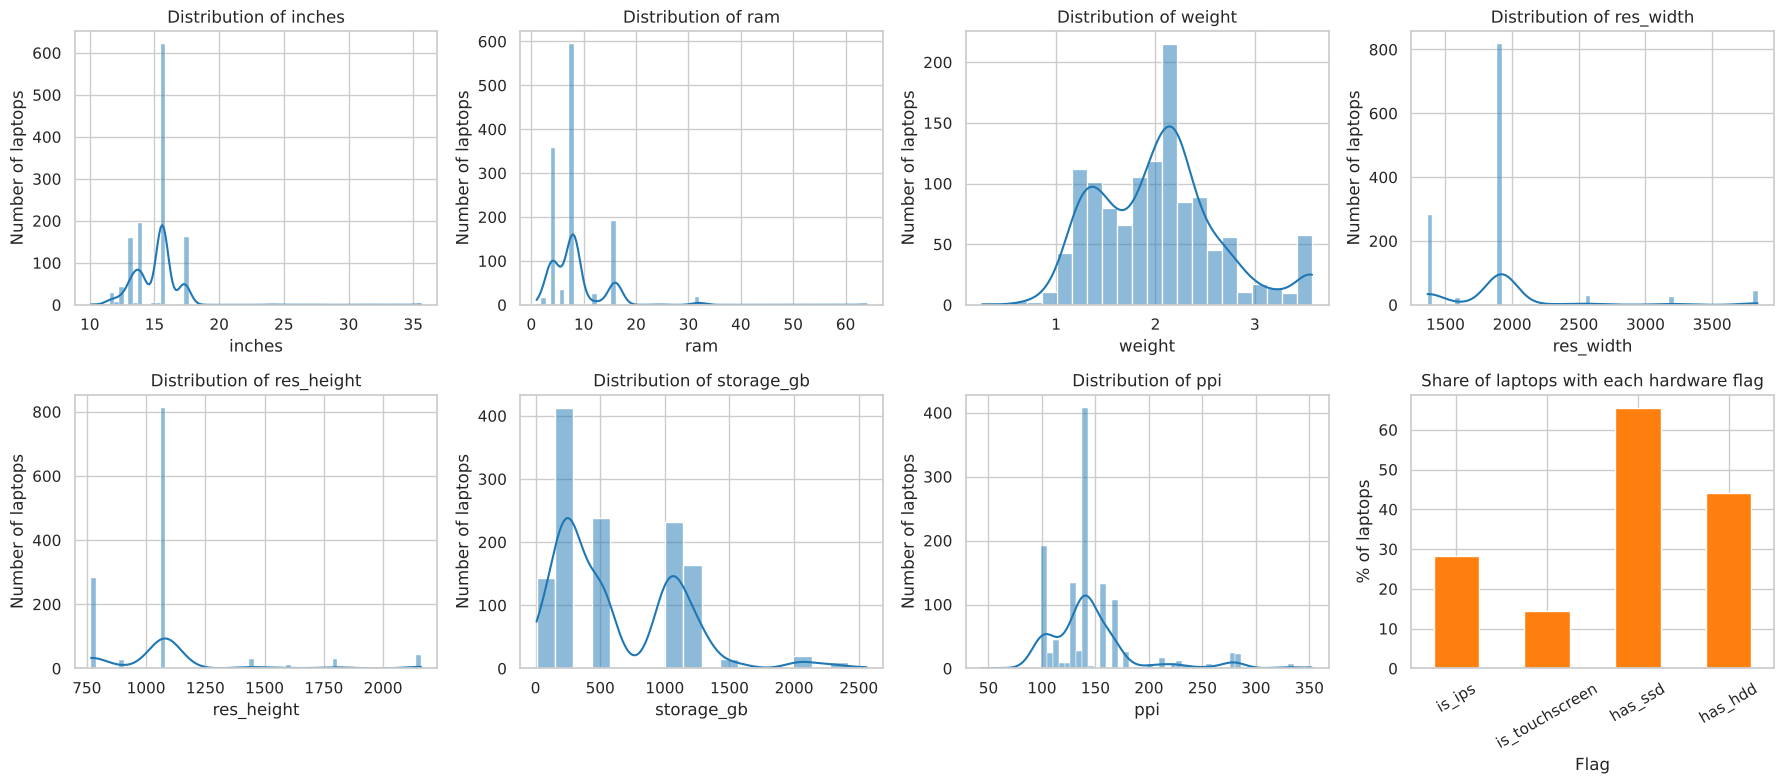

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), CONT_COLS):
    sns.histplot(df[col], kde=True, ax=ax, color=sns.color_palette(PALETTE)[0])
    ax.set_title(f"Distribution of {col}"); ax.set_xlabel(col); ax.set_ylabel("Number of laptops")
ax = axes.ravel()[-1]
df[FLAG_COLS].mean().mul(100).plot.bar(ax=ax, color=sns.color_palette(PALETTE)[1])
ax.set_title("Share of laptops with each hardware flag"); ax.set_xlabel("Flag"); ax.set_ylabel("% of laptops")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("../figures/clu_feature_distributions.png", bbox_inches="tight")
plt.show()

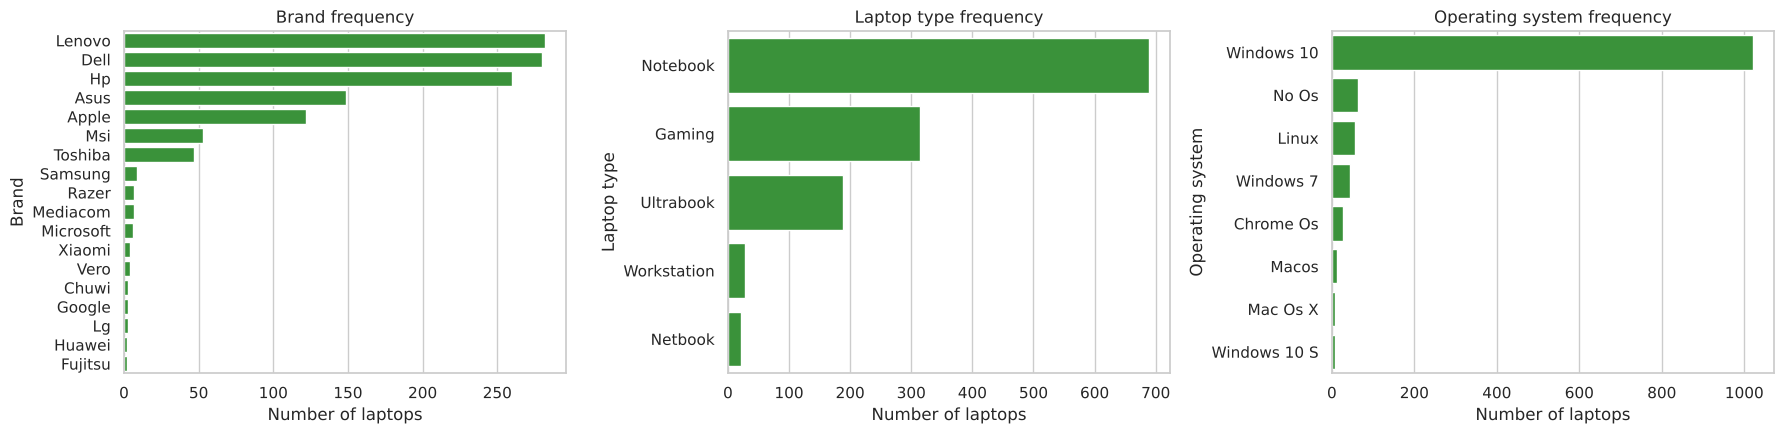

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col, title in zip(axes, ["brand", "type", "os"], ["Brand", "Laptop type", "Operating system"]):
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order, ax=ax, color=sns.color_palette(PALETTE)[2])
    ax.set_title(f"{title} frequency"); ax.set_xlabel("Number of laptops"); ax.set_ylabel(title)
plt.tight_layout()
plt.savefig("../figures/clu_category_counts.png", bbox_inches="tight")
plt.show()

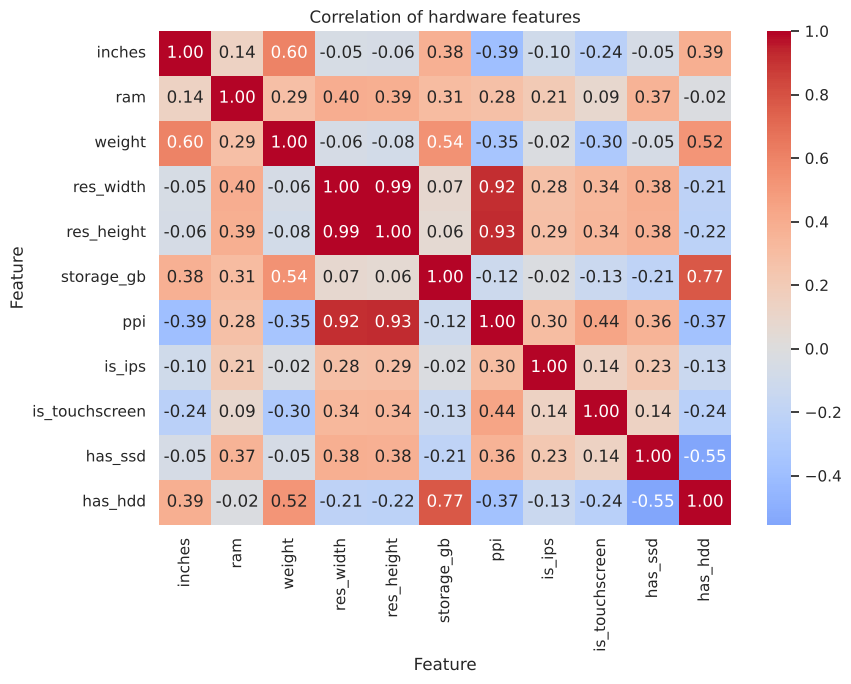

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[CONT_COLS + FLAG_COLS].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation of hardware features")
plt.xlabel("Feature"); plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("../figures/clu_correlation_heatmap.png", bbox_inches="tight")
plt.show()

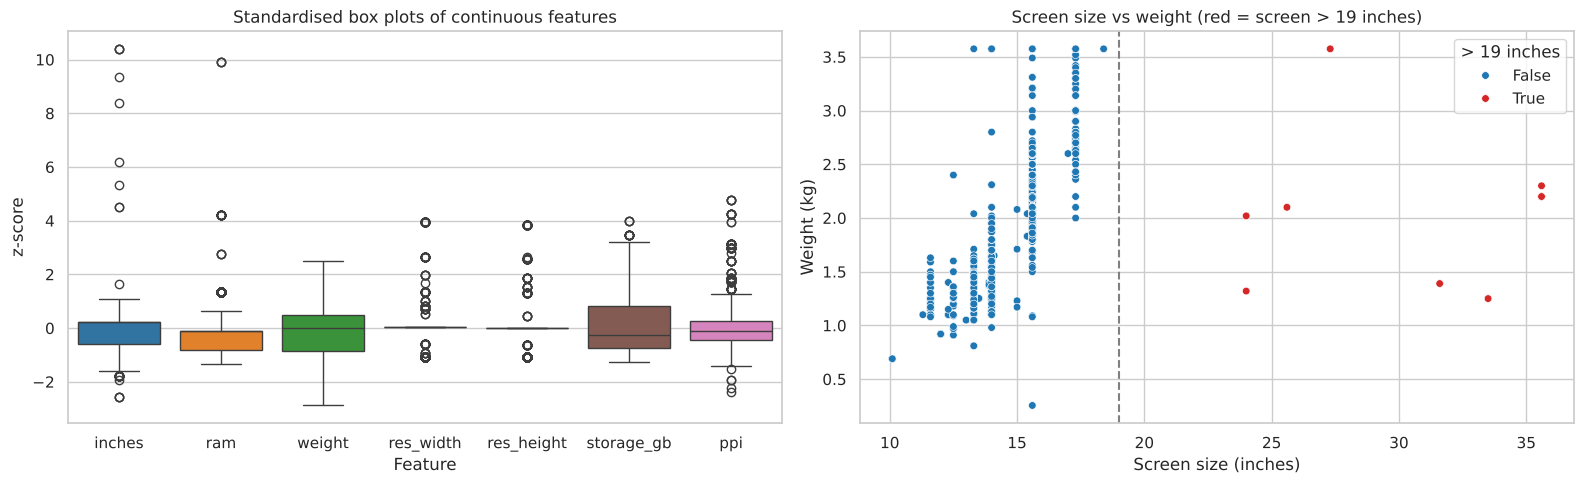

,inches,ram,weight,res_width,res_height,storage_gb,ppi,brand,type
391,25.6,8.0,2.100,1920,1080,1280.0,86.051061,Lenovo,Notebook
397,35.6,4.0,2.200,1920,1080,500.0,61.879415,Lenovo,Notebook
412,35.6,8.0,2.300,1920,1080,1024.0,61.879415,Asus,Notebook
413,27.3,16.0,3.575,2560,1440,1280.0,107.590094,Dell,Gaming
427,24.0,24.0,1.320,2560,1440,512.0,122.383732,Lenovo,Ultrabook
447,33.5,8.0,1.250,2256,1504,256.0,80.936554,Microsoft,Ultrabook
512,24.0,8.0,2.020,1920,1080,256.0,91.787799,Lenovo,Notebook
578,31.6,4.0,1.390,1366,768,128.0,49.591546,Dell,Gaming
655,35.6,4.0,2.200,1366,768,128.0,44.019462,Lenovo,Notebook


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=(df[CONT_COLS] - df[CONT_COLS].mean()) / df[CONT_COLS].std(), palette=PALETTE, ax=axes[0])
axes[0].set_title("Standardised box plots of continuous features")
axes[0].set_xlabel("Feature"); axes[0].set_ylabel("z-score")
sns.scatterplot(data=df, x="inches", y="weight", hue=df["inches"] > 19,
                palette={False: "tab:blue", True: "tab:red"}, ax=axes[1], s=30)
axes[1].axvline(19, ls="--", c="grey")
axes[1].set_title("Screen size vs weight (red = screen > 19 inches)")
axes[1].set_xlabel("Screen size (inches)"); axes[1].set_ylabel("Weight (kg)")
axes[1].legend(title="> 19 inches")
plt.tight_layout()
plt.savefig("../figures/clu_outliers.png", bbox_inches="tight")
plt.show()
df.loc[df["inches"] > 19, CONT_COLS + ["brand", "type"]]

## 4. Preprocessing

In [ ]:
n0 = len(df)
data = df[df["inches"] <= 19].copy()
n1 = len(data)
data = data.drop_duplicates(subset=CONT_COLS + FLAG_COLS + BRAND_COLS + OS_COLS + TYPE_COLS).reset_index(drop=True)
print(f"Rows: {n0} -> {n1} after removing invalid screens -> {len(data)} after removing duplicates")

lo, hi = data[CONT_COLS].quantile(0.01), data[CONT_COLS].quantile(0.99)
data[CONT_COLS] = data[CONT_COLS].clip(lo, hi, axis=1)

FIT_COLS = CONT_COLS + FLAG_COLS
preprocessor = ColumnTransformer([("scale", StandardScaler(), CONT_COLS),
                                  ("flags", "passthrough", FLAG_COLS)])
X_scaled = preprocessor.fit_transform(data[FIT_COLS])
y_ref = data["type"]            # reference labels — NOT used for fitting
print("Feature matrix used for clustering:", X_scaled.shape)

Rows: 1243 -> 1234 after removing invalid screens -> 986 after removing duplicates
Feature matrix used for clustering: (986, 11)


In [ ]:
def evaluate_clustering(X, labels, name):
    """The three mandatory internal metrics for one clustering result."""
    return {"Algorithm": name,
            "n_clusters": len(np.unique(labels)),
            "Silhouette": silhouette_score(X, labels),
            "Davies-Bouldin": davies_bouldin_score(X, labels),
            "Calinski-Harabasz": calinski_harabasz_score(X, labels)}

results = []

## 5. Feature-set ablation

In [ ]:
def winsorised(frame):
    return frame[CONT_COLS].clip(frame[CONT_COLS].quantile(0.01), frame[CONT_COLS].quantile(0.99), axis=1)

options = {
    "A: all features, all standardised":
        StandardScaler().fit_transform(pd.concat([winsorised(data), data[FLAG_COLS + BRAND_COLS + OS_COLS]], axis=1)),
    "B: specs scaled + flags + brand/OS as 0/1":
        np.hstack([StandardScaler().fit_transform(winsorised(data)), data[FLAG_COLS + BRAND_COLS + OS_COLS].values]),
    "C: specs scaled + flags (chosen)": X_scaled,
}
rows = []
for name, Xo in options.items():
    for k in [3, 4, 5]:
        lab = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(Xo)
        rows.append({"Feature set": name, "k": k, "n_features": Xo.shape[1],
                     "Silhouette": silhouette_score(Xo, lab),
                     "Smallest cluster": np.bincount(lab).min()})
ablation = pd.DataFrame(rows)
ablation.pivot(index="Feature set", columns="k", values="Silhouette").round(3)

k,3,4,5
Feature set,,,
"A: all features, all standardised",0.108,0.114,0.135
B: specs scaled + flags + brand/OS as 0/1,0.251,0.201,0.201
C: specs scaled + flags (chosen),0.304,0.255,0.268


In [ ]:
ablation.pivot(index='Feature set', columns='k', values='Smallest cluster')

k,3,4,5
Feature set,,,
"A: all features, all standardised",92,3,9
B: specs scaled + flags + brand/OS as 0/1,69,67,68
C: specs scaled + flags (chosen),69,67,68


## 6. K-Means clustering
### 6.1 Elbow curve and silhouette vs k

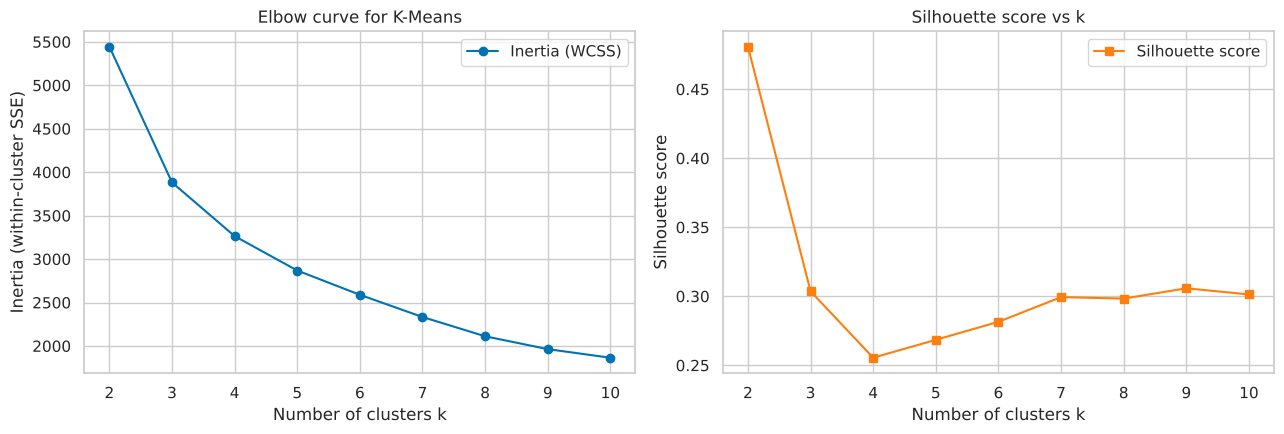

,k,inertia,silhouette,davies_bouldin,smallest_cluster
0,2,5445.0043,0.4809,0.9657,98
1,3,3881.9668,0.3036,1.1372,69
2,4,3263.9856,0.2555,1.2668,67
3,5,2868.3034,0.2684,1.1890,68
4,6,2588.9194,0.2815,1.1365,67
5,7,2333.5008,0.2994,1.1261,66
6,8,2111.6717,0.2983,1.1532,26
7,9,1963.7790,0.3058,1.1627,26
8,10,1864.7146,0.3013,1.3207,26


In [ ]:
k_stats = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    k_stats.append({"k": k, "inertia": km.inertia_,
                    "silhouette": silhouette_score(X_scaled, km.labels_),
                    "davies_bouldin": davies_bouldin_score(X_scaled, km.labels_),
                    "smallest_cluster": np.bincount(km.labels_).min()})
k_stats = pd.DataFrame(k_stats)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(k_stats["k"], k_stats["inertia"], "o-", label="Inertia (WCSS)")
axes[0].set_title("Elbow curve for K-Means")
axes[0].set_xlabel("Number of clusters k"); axes[0].set_ylabel("Inertia (within-cluster SSE)")
axes[0].legend()
axes[1].plot(k_stats["k"], k_stats["silhouette"], "s-", color="tab:orange", label="Silhouette score")
axes[1].set_title("Silhouette score vs k")
axes[1].set_xlabel("Number of clusters k"); axes[1].set_ylabel("Silhouette score")
axes[1].legend()
plt.tight_layout()
plt.savefig("../figures/clu_kmeans_elbow.png", bbox_inches="tight")
plt.show()
k_stats.round(4)

In [ ]:
# k = 2 gives the highest silhouette, but it only separates high-resolution premium laptops
# from everything else — too coarse to be a useful segmentation:
km2 = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
data.assign(cluster=km2).groupby("cluster")[FIT_COLS].mean().round(2)

,inches,ram,weight,res_width,res_height,storage_gb,ppi,is_ips,is_touchscreen,has_ssd,has_hdd
cluster,,,,,,,,,,,
0,15.05,8.25,2.06,1781.26,1003.45,614.12,136.94,0.28,0.12,0.64,0.44
1,14.15,13.04,1.68,3221.06,1846.04,599.35,261.66,0.55,0.56,0.94,0.14


In [ ]:
# Rule (parsimony): the SMALLEST k >= 3 whose silhouette is within 0.01 of the best k >= 3.
# Silhouette barely changes from k = 3 to k = 10 here, so extra clusters add complexity without
# better separation; this also matches the elbow. Set K_OVERRIDE if the team disagrees.
K_OVERRIDE = None
cand = k_stats.query("k >= 3")
best_k = K_OVERRIDE or int(cand.loc[cand["silhouette"] >= cand["silhouette"].max() - 0.01, "k"].min())
print(f"Best silhouette (k>=3): {cand['silhouette'].max():.4f} at k={int(cand.loc[cand['silhouette'].idxmax(),'k'])}")
print("Chosen k:", best_k)

Best silhouette (k>=3): 0.3058 at k=9
Chosen k: 3


### 6.2 Final K-Means model

In [ ]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans.fit_predict(X_scaled)
results.append(evaluate_clustering(X_scaled, kmeans_labels, f"K-Means (k={best_k})"))
print("Cluster sizes:", np.bincount(kmeans_labels))

Cluster sizes: [433 484  69]


## 7. Agglomerative hierarchical clustering
### 7.1 Dendrograms — comparing linkage strategies

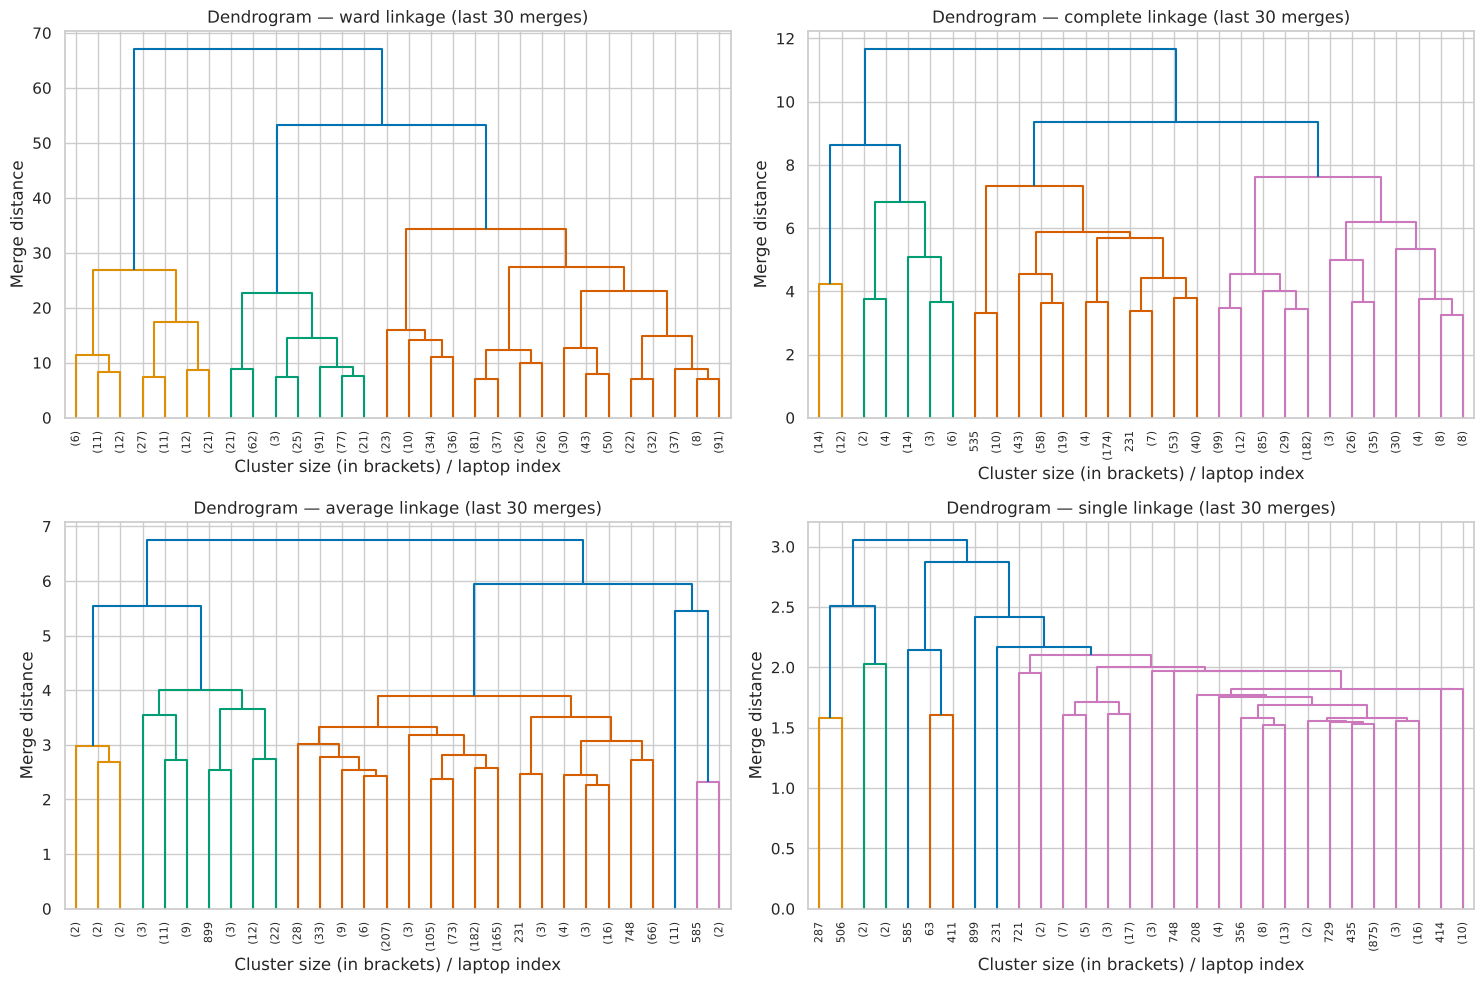

In [ ]:
LINKAGES = ["ward", "complete", "average", "single"]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, method in zip(axes.ravel(), LINKAGES):
    Z = linkage(X_scaled, method=method)
    dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, leaf_rotation=90, leaf_font_size=8)
    ax.set_title(f"Dendrogram — {method} linkage (last 30 merges)")
    ax.set_xlabel("Cluster size (in brackets) / laptop index"); ax.set_ylabel("Merge distance")
plt.tight_layout()
plt.savefig("../figures/clu_dendrograms.png", bbox_inches="tight")
plt.show()

### 7.2 Linkage comparison at the same k

In [ ]:
link_rows = []
for method in LINKAGES:
    lab = AgglomerativeClustering(n_clusters=best_k, linkage=method).fit_predict(X_scaled)
    row = evaluate_clustering(X_scaled, lab, method)
    row["cluster_sizes"] = np.bincount(lab).tolist()
    link_rows.append(row)
linkage_table = pd.DataFrame(link_rows).rename(columns={"Algorithm": "Linkage"})
linkage_table.round(4)

,Linkage,n_clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz,cluster_sizes
0,ward,3,0.2770,1.1379,445.6956,"[586, 100, 300]"
1,complete,3,0.2694,1.1953,409.1104,"[55, 521, 410]"
2,average,3,0.4627,0.8264,238.9211,"[67, 14, 905]"
3,single,3,0.3733,0.6729,28.9730,"[6, 3, 977]"


In [ ]:
# A high silhouette from one giant cluster + a few singletons is not a useful segmentation,
# so only linkages whose smallest cluster has at least 5% of the laptops are eligible.
min_size = 0.05 * len(X_scaled)
eligible = linkage_table[linkage_table["cluster_sizes"].apply(min) >= min_size]
best_link = (eligible.sort_values("Silhouette", ascending=False).iloc[0]["Linkage"]
             if len(eligible) else "ward")   # Ward fallback: it minimises within-cluster variance

agglo = AgglomerativeClustering(n_clusters=best_k, linkage=best_link)
agglo_labels = agglo.fit_predict(X_scaled)
results.append(evaluate_clustering(X_scaled, agglo_labels, f"Agglomerative ({best_link}, k={best_k})"))
print("Eligible linkages:", eligible["Linkage"].tolist())
print("Chosen linkage:", best_link, "| cluster sizes:", np.bincount(agglo_labels))

Eligible linkages: ['ward', 'complete']
Chosen linkage: ward | cluster sizes: [586 100 300]


## 8. Comparative results table

In [ ]:
results_df = pd.DataFrame(results).sort_values("Silhouette", ascending=False).reset_index(drop=True)
results_df.style.format({"Silhouette": "{:.4f}", "Davies-Bouldin": "{:.4f}", "Calinski-Harabasz": "{:.2f}"}) \
    .highlight_max(subset=["Silhouette", "Calinski-Harabasz"], color="#c6efce") \
    .highlight_min(subset=["Davies-Bouldin"], color="#c6efce")

,Algorithm,n_clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means (k=3),3,0.3036,1.1372,483.63
1,"Agglomerative (ward, k=3)",3,0.2770,1.1379,445.70


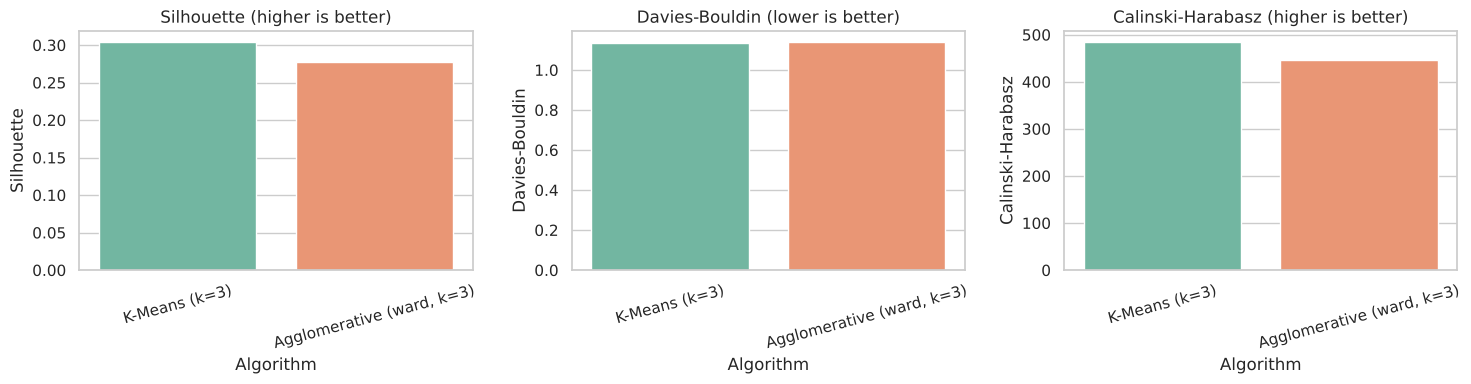

Agreement between the two algorithms (ARI): 0.458


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, note in zip(axes, ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz"],
                            ["higher is better", "lower is better", "higher is better"]):
    sns.barplot(data=results_df, x="Algorithm", y=metric, hue="Algorithm", palette="Set2", ax=ax, legend=False)
    ax.set_title(f"{metric} ({note})"); ax.set_xlabel("Algorithm"); ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig("../figures/clu_metric_comparison.png", bbox_inches="tight")
plt.show()
print("Agreement between the two algorithms (ARI):", round(adjusted_rand_score(kmeans_labels, agglo_labels), 3))

## 9. PCA visualisation — every algorithm

Variance explained: PC1 = 41.8%, PC2 = 33.7%, total = 75.4%


,PC1,PC2
ppi,0.546,-0.041
res_height,0.529,0.138
res_width,0.526,0.149
ram,0.231,0.363
inches,-0.175,0.518
weight,-0.157,0.528
has_ssd,0.112,0.000
has_hdd,-0.098,0.187
is_touchscreen,0.087,-0.041
is_ips,0.077,0.017


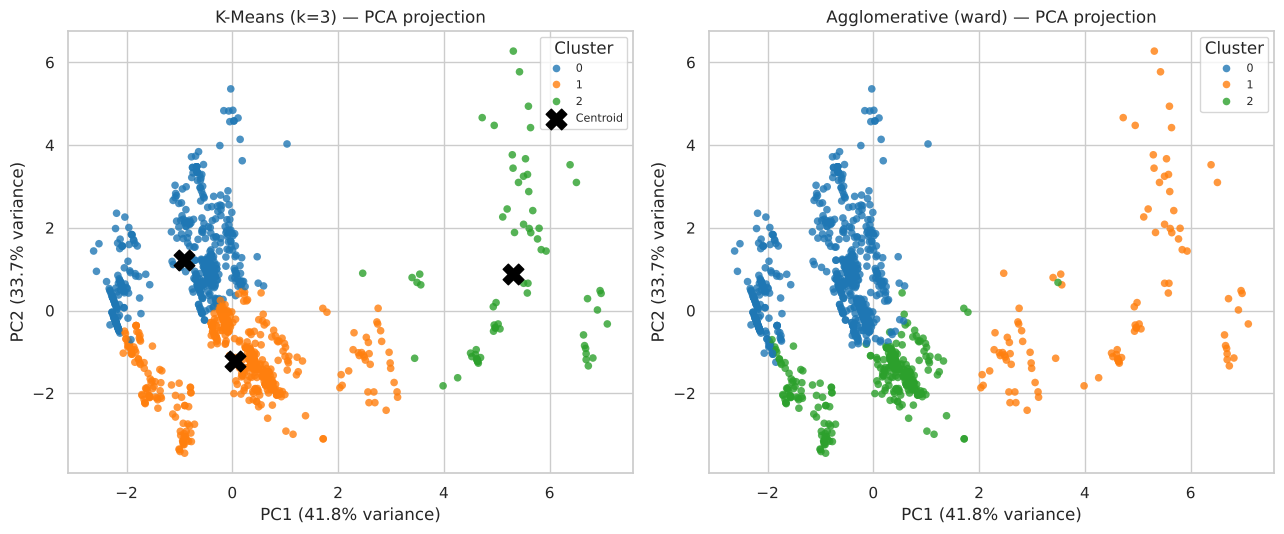

In [ ]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
evr = pca.explained_variance_ratio_
print(f"Variance explained: PC1 = {evr[0]:.1%}, PC2 = {evr[1]:.1%}, total = {evr.sum():.1%}")

loadings = pd.DataFrame(pca.components_.T, index=FIT_COLS, columns=["PC1", "PC2"])
display(loadings.round(3).sort_values("PC1", key=abs, ascending=False))

def plot_2d(emb, label_sets, titles, xlab, ylab, fname, centroids=None, legend_title="Cluster"):
    fig, axes = plt.subplots(1, len(label_sets), figsize=(6.5 * len(label_sets), 5.5))
    axes = np.atleast_1d(axes)
    for i, (ax, labels, title) in enumerate(zip(axes, label_sets, titles)):
        sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=labels, palette=PALETTE,
                        s=30, alpha=0.8, ax=ax, edgecolor="none")
        if centroids is not None and centroids[i] is not None:
            ax.scatter(centroids[i][:, 0], centroids[i][:, 1], marker="X", s=220, c="black", label="Centroid")
        ax.set_title(title); ax.set_xlabel(xlab); ax.set_ylabel(ylab)
        ax.legend(title=legend_title, loc="best", fontsize=8)
    plt.tight_layout()
    plt.savefig(f"../figures/{fname}", bbox_inches="tight")
    plt.show()

plot_2d(X_pca, [kmeans_labels, agglo_labels],
        [f"K-Means (k={best_k}) — PCA projection", f"Agglomerative ({best_link}) — PCA projection"],
        f"PC1 ({evr[0]:.1%} variance)", f"PC2 ({evr[1]:.1%} variance)", "clu_pca_clusters.png",
        centroids=[pca.transform(kmeans.cluster_centers_), None])

## 10. t-SNE visualisation — both algorithms

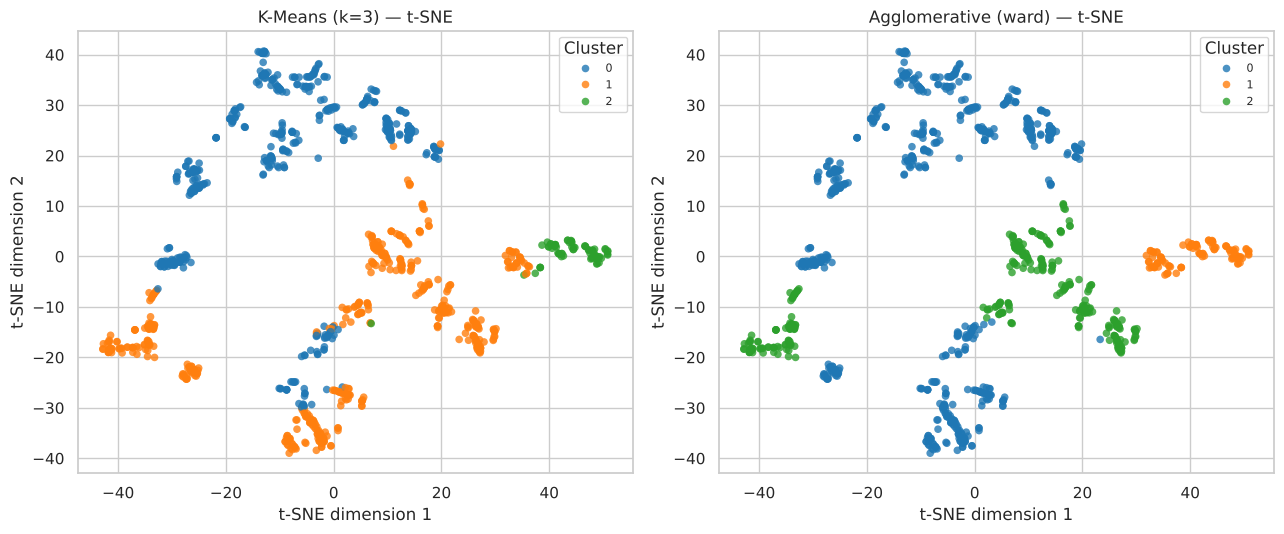

In [ ]:
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_scaled)
plot_2d(X_tsne, [kmeans_labels, agglo_labels],
        [f"K-Means (k={best_k}) — t-SNE", f"Agglomerative ({best_link}) — t-SNE"],
        "t-SNE dimension 1", "t-SNE dimension 2", "clu_tsne_clusters.png")

## 11. Post-hoc validation against laptop type


,Algorithm,ARI,NMI
0,K-Means (k=3),0.0715,0.1196
1,"Agglomerative (ward, k=3)",0.1538,0.1487


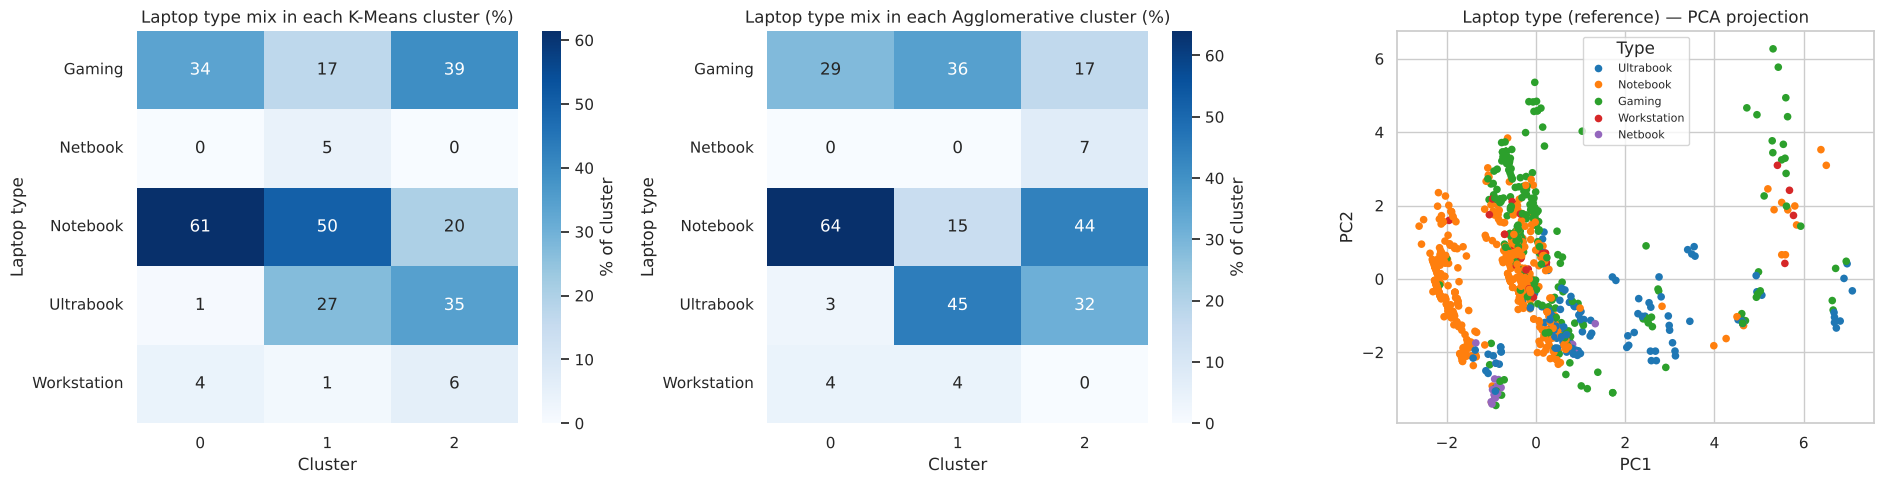

In [ ]:
ext = pd.DataFrame([
    {"Algorithm": f"K-Means (k={best_k})",
     "ARI": adjusted_rand_score(y_ref, kmeans_labels), "NMI": normalized_mutual_info_score(y_ref, kmeans_labels)},
    {"Algorithm": f"Agglomerative ({best_link}, k={best_k})",
     "ARI": adjusted_rand_score(y_ref, agglo_labels), "NMI": normalized_mutual_info_score(y_ref, agglo_labels)},
])
display(ext.round(4))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, lab, t in zip(axes[:2], [kmeans_labels, agglo_labels], ["K-Means", "Agglomerative"]):
    ct = pd.crosstab(y_ref, lab, normalize="columns").mul(100)
    sns.heatmap(ct, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar_kws={"label": "% of cluster"})
    ax.set_title(f"Laptop type mix in each {t} cluster (%)"); ax.set_xlabel("Cluster"); ax.set_ylabel("Laptop type")
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_ref, palette=PALETTE, s=30, ax=axes[2], edgecolor="none")
axes[2].set_title("Laptop type (reference) — PCA projection")
axes[2].set_xlabel("PC1"); axes[2].set_ylabel("PC2"); axes[2].legend(title="Type", fontsize=8)
plt.tight_layout()
plt.savefig("../figures/clu_type_validation.png", bbox_inches="tight")
plt.show()

## 12. Cluster profiling — what defines each segment?

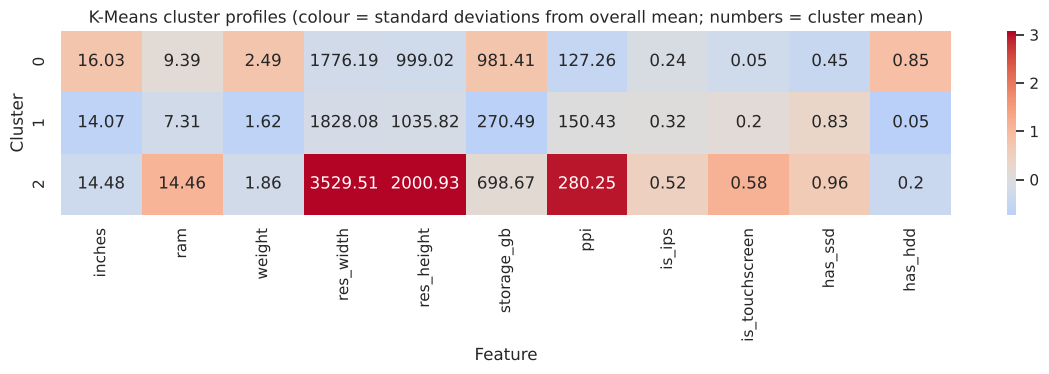

,inches,ram,weight,res_width,res_height,storage_gb,ppi,is_ips,is_touchscreen,has_ssd,has_hdd,n_laptops
cluster,,,,,,,,,,,,
0,16.03,9.39,2.49,1776.19,999.02,981.41,127.26,0.24,0.05,0.45,0.85,433
1,14.07,7.31,1.62,1828.08,1035.82,270.49,150.43,0.32,0.20,0.83,0.05,484
2,14.48,14.46,1.86,3529.51,2000.93,698.67,280.25,0.52,0.58,0.96,0.20,69


In [ ]:
profile = data.assign(cluster=kmeans_labels)
cluster_means = profile.groupby("cluster")[FIT_COLS].mean()
cluster_means["n_laptops"] = profile["cluster"].value_counts().sort_index()

z = (cluster_means[FIT_COLS] - data[FIT_COLS].mean()) / data[FIT_COLS].std()
plt.figure(figsize=(12, 1.5 + best_k * 0.8))
sns.heatmap(z, cmap="coolwarm", center=0, annot=cluster_means[FIT_COLS].round(2), fmt="")
plt.title("K-Means cluster profiles (colour = standard deviations from overall mean; numbers = cluster mean)")
plt.xlabel("Feature"); plt.ylabel("Cluster")
plt.tight_layout()
plt.savefig("../figures/clu_cluster_profiles.png", bbox_inches="tight")
plt.show()
cluster_means.round(2)

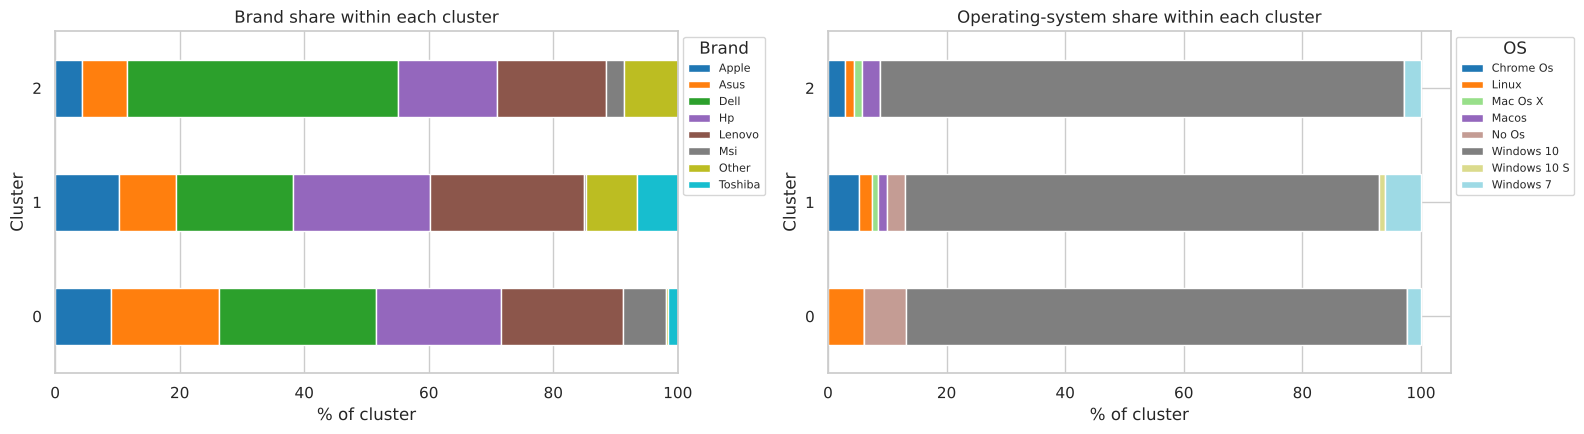

In [ ]:
# Brand and OS were NOT used for fitting — here they describe who makes the laptops in each segment
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
top_brands = data["brand"].value_counts().index[:7]
bmix = pd.crosstab(profile["cluster"], profile["brand"].where(profile["brand"].isin(top_brands), "Other"),
                   normalize="index").mul(100)
bmix.plot.barh(stacked=True, ax=axes[0], colormap="tab10")
axes[0].set_title("Brand share within each cluster"); axes[0].set_xlabel("% of cluster"); axes[0].set_ylabel("Cluster")
axes[0].legend(title="Brand", bbox_to_anchor=(1, 1), fontsize=8)
omix = pd.crosstab(profile["cluster"], profile["os"], normalize="index").mul(100)
omix.plot.barh(stacked=True, ax=axes[1], colormap="tab20")
axes[1].set_title("Operating-system share within each cluster"); axes[1].set_xlabel("% of cluster"); axes[1].set_ylabel("Cluster")
axes[1].legend(title="OS", bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout()
plt.savefig("../figures/clu_brand_os_mix.png", bbox_inches="tight")
plt.show()

## 13. Save models and cluster assignments

In [ ]:
joblib.dump({"preprocessor": preprocessor, "kmeans": kmeans, "features": FIT_COLS},
            "../models/kmeans_pipeline.pkl")
joblib.dump({"preprocessor": preprocessor, "agglomerative": agglo, "features": FIT_COLS,
             "labels": agglo_labels}, "../models/agglomerative.pkl")
data.assign(kmeans_cluster=kmeans_labels, agglo_cluster=agglo_labels) \
    [CONT_COLS + FLAG_COLS + ["brand", "os", "type", "kmeans_cluster", "agglo_cluster"]] \
    .to_csv("../models/cluster_assignments.csv", index=False)
print("Saved models and cluster assignments to ../models/")

Saved models and cluster assignments to ../models/
